# Extended Analysis: cross-validation, threshold tuning and SHAP

Builds on `Modelling.ipynb`, using the same data and the same feature engineering, and adds three things:

1. **Stratified 5-fold cross-validation**, with imputation and SMOTE fitted inside every fold so each validation fold is completely unseen.
2. **Decision-threshold tuning** on out-of-fold predictions from the training data, so the test set is not used to pick the threshold.
3. **SHAP** values to explain the XGBoost model.

Run on CPU. XGBoost uses `tree_method='hist'` on CPU instead of the GPU settings in `Modelling.ipynb`, so some numbers differ slightly. The neural network is not repeated here.

In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score,
                             recall_score, f1_score, precision_recall_curve, confusion_matrix)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier
import shap

warnings.filterwarnings('ignore')
SEED = 42
REF_DATE = pd.Timestamp('2026-03-09')   # same reference date as Modelling.ipynb

## 1. Load the final dataset

In [2]:
df_raw = pd.read_excel('../Data/Merged_Final_Dataset_With_Sentiment.xlsx', sheet_name='Sheet1')
print(f"Rows: {len(df_raw):,}  Columns: {df_raw.shape[1]}")
print(df_raw['CompanyStatus'].value_counts().to_string())
print(f"\nDistressed (Target Value = 1): {df_raw['Target Value'].sum():,} ({df_raw['Target Value'].mean():.2%})")

Rows: 24,748  Columns: 96
CompanyStatus
Active                             23523
Active - Proposal to Strike off     1194
Liquidation                           29
Voluntary Arrangement                  2

Distressed (Target Value = 1): 1,225 (4.95%)


## 2. Feature engineering (same steps as `Modelling.ipynb`)

Drop identifiers and matching columns, average the individual review stars, remove constant columns, one-hot encode categories, count previous names and extra SIC codes, compute company age and a name-change tenure category, create the two overdue flags (confirmation statement and accounts, against 9 March 2026), and map hygiene ratings to numbers.

In [3]:
def build_features(df):
    df = df.drop(['CompanyName','RegAddress.CareOf','RegAddress.AddressLine1','RegAddress.PostTown',
                  'RegAddress.County','RegAddress.Country',' RegAddress.AddressLine2','RegAddress.PostCode',
                  'CompanyStatus','CountryOfOrigin','LimitedPartnerships.NumGenPartners',
                  'LimitedPartnerships.NumLimPartners','URI','PostCode_Validity_x','Potential_matches_name',
                  'Potential_matches_address','Potential_matches_businessid','Final_Business_ID','Single_remove',
                  'MatchScore','Match_Method','AddressLine1','AddressLine2','AddressLine3','AddressLine4',
                  'BusinessTypeID','FHRSID','BusinessName','Latitude','LocalAuthorityBusinessID',
                  'LocalAuthorityCode','Longitude','RatingKey','RightToReply','PostCode_Validity_y'], axis=1)

    # Average of the individual review stars
    ratings = df['Google_Individual_Review_Ratings'].str.split('|')
    df['Latest_Average'] = ratings.apply(lambda x: np.mean([int(i.strip()) for i in x]) if isinstance(x, list) else np.nan)
    df = df.drop(columns=['Google_Review_Texts', 'Google_Individual_Review_Ratings'])

    def drop_constant(d):
        n = d.nunique()
        return d[n[n > 1].index]

    df = drop_constant(df)
    df = pd.get_dummies(df, columns=['SchemeType'], drop_first=True, dtype=int)
    df = pd.get_dummies(df, columns=['CompanyCategory','Accounts.AccountCategory','SICCode.SicText_1','BusinessType'],
                        dummy_na=True, dtype=int)
    df = drop_constant(df)

    name_cols = [c for c in df.columns if '.CompanyName' in c]
    df['Total_Previous_Names'] = df[name_cols].notna().sum(axis=1)
    df = df.drop(columns=name_cols)
    sic_cols = ['SICCode.SicText_2','SICCode.SicText_3','SICCode.SicText_4']
    df['Total_Other_Codes'] = df[sic_cols].notna().sum(axis=1)
    df = df.drop(columns=sic_cols)

    df['IncorporationDate'] = pd.to_datetime(df['IncorporationDate'], errors='coerce', dayfirst=True)
    df['Months_Since_Incorp'] = ((REF_DATE.year - df['IncorporationDate'].dt.year) * 12 +
                                 (REF_DATE.month - df['IncorporationDate'].dt.month))

    date_cols = ['IncorporationDate'] + [c for c in df.columns if '.CONDATE' in c]
    for c in date_cols:
        df[c] = pd.to_datetime(df[c], errors='coerce', dayfirst=True)
    def avg_change_interval(row):
        ev = sorted([row[d] for d in date_cols if pd.notna(row[d])])
        if len(ev) == 1:
            return (REF_DATE.year - ev[0].year) * 12 + (REF_DATE.month - ev[0].month)
        gaps = [(ev[i+1].year - ev[i].year) * 12 + (ev[i+1].month - ev[i].month) for i in range(len(ev) - 1)]
        return sum(gaps) / len(gaps)
    interval = df.apply(avg_change_interval, axis=1)
    df['Tenure_Category'] = interval.apply(lambda v: 'Unknown' if pd.isna(v) else
                                           'Frequent_Changes' if v <= 12 else
                                           'Moderate_Stability' if v <= 48 else 'High_Stability_Ongoing')
    df = pd.get_dummies(df, columns=['Tenure_Category'], dtype=int)
    df = df.drop(columns=[c for c in df.columns if '.CONDATE' in c] + ['Rating Rounded'], errors='ignore')

    conf_due = pd.to_datetime(df['ConfStmtNextDueDate'], errors='coerce', dayfirst=True)
    df['Is_Filing_Overdue'] = (conf_due < REF_DATE).astype(int)
    acc_due = pd.to_datetime(df['Accounts.NextDueDate'], errors='coerce', dayfirst=True)
    df['Accounts_Overdue'] = (acc_due < REF_DATE).astype(int)

    df = df.drop(columns=['ConfStmtNextDueDate',' ConfStmtLastMadeUpDate','IncorporationDate',
                          'Accounts.NextDueDate','Accounts.LastMadeUpDate','Accounts.AccountRefDay',
                          'Accounts.AccountRefMonth','Returns.NextDueDate','Returns.LastMadeUpDate',
                          'LocalAuthorityName','RatingDate','PostCode'], errors='ignore')

    bool_cols = df.select_dtypes(include=['bool']).columns
    df[bool_cols] = df[bool_cols].astype(int)
    rating_map = {'5': 5, '4': 4, '3': 3, '2': 2, '1': 1, '0': 0, 'Pass': 4, 'Pass and Eat Safe': 5,
                  'Improvement Required': 1, 'AwaitingInspection': np.nan, 'AwaitingPublication': np.nan,
                  'Exempt': np.nan}
    df['RatingValue'] = df['RatingValue'].astype(str).map(rating_map)
    return df

df = build_features(df_raw)
y = df['Target Value']
X_all = df.drop(columns=[' CompanyNumber', 'Target Value']).select_dtypes(include=[np.number]).astype(float)
OVERDUE = ['Is_Filing_Overdue', 'Accounts_Overdue']
X_stress = X_all.drop(columns=OVERDUE)

print(f"Features (all): {X_all.shape[1]}  |  Stress-test features (no overdue flags): {X_stress.shape[1]}")
print(f"Missing cells to impute: {int(X_all.isna().sum().sum()):,}")
print("\nOverdue rates by class:")
print(df.groupby('Target Value')[OVERDUE].mean().round(3).to_string())

Features (all): 69  |  Stress-test features (no overdue flags): 67
Missing cells to impute: 33,750

Overdue rates by class:
              Is_Filing_Overdue  Accounts_Overdue
Target Value                                     
0                         0.131             0.065
1                         0.811             0.647


## 3. Reproduce the headline result

First, run the exact pipeline from `Modelling.ipynb` for logistic regression with all features, to confirm the feature engineering above matches. `Modelling.ipynb` reports a test ROC-AUC of **0.930**.

In [4]:
def impute_all_rows(X):
    scaler = MinMaxScaler()
    filled = KNNImputer(n_neighbors=5, weights='distance').fit_transform(scaler.fit_transform(X))
    return pd.DataFrame(scaler.inverse_transform(filled), columns=X.columns, index=X.index)

X_orig = impute_all_rows(X_all)
Xtr_l, Xte_l, ytr_l, yte_l = train_test_split(X_orig, y, test_size=0.2, random_state=SEED, stratify=y)
lr_check = LogisticRegression(max_iter=1000).fit(Xtr_l, ytr_l)
print(f"Logistic regression, all features, original pipeline: test ROC-AUC = {roc_auc_score(yte_l, lr_check.predict_proba(Xte_l)[:, 1]):.3f}")

Logistic regression, all features, original pipeline: test ROC-AUC = 0.930


## 4. Train/test split and imputation

Split into an 80/20 stratified train and test set, then fit the scaler and KNN imputer on the training rows and apply them to both sets. The same imputation step is used inside every cross-validation fold in section 6.

In [5]:
class ScaledKNNImputer(BaseEstimator, TransformerMixin):
    """Scale to 0-1, fill gaps with KNN (k=5, distance-weighted), scale back."""
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors
    def fit(self, X, y=None):
        self.columns_ = list(X.columns)
        self.scaler_ = MinMaxScaler().fit(X)
        self.imputer_ = KNNImputer(n_neighbors=self.n_neighbors, weights='distance').fit(self.scaler_.transform(X))
        return self
    def transform(self, X):
        filled = self.imputer_.transform(self.scaler_.transform(X))
        return pd.DataFrame(self.scaler_.inverse_transform(filled), columns=self.columns_, index=X.index)

Xtr_raw, Xte_raw, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=SEED, stratify=y)
imputer = ScaledKNNImputer().fit(Xtr_raw)
X_train, X_test = imputer.transform(Xtr_raw), imputer.transform(Xte_raw)
X_train_st, X_test_st = X_train.drop(columns=OVERDUE), X_test.drop(columns=OVERDUE)
print(f"Train: {len(X_train):,} ({y_train.sum()} distressed)  |  Test: {len(X_test):,} ({y_test.sum()} distressed)")
print(f"NaNs left - train: {int(X_train.isna().sum().sum())}, test: {int(X_test.isna().sum().sum())}")

Train: 19,798 (980 distressed)  |  Test: 4,950 (245 distressed)
NaNs left - train: 0, test: 0


## 5. Models on this split

The same model set-ups as `Modelling.ipynb`: logistic regression with all features, then the stress test without the overdue flags. Metrics for the distressed class are at the default 0.5 threshold. The last column repeats the test AUC reported in `Modelling.ipynb` for comparison; small differences come from running XGBoost on CPU and fitting imputation on the training rows.

In [6]:
def make_xgb():
    return XGBClassifier(tree_method='hist', n_estimators=1200, max_depth=6, learning_rate=0.04,
                         scale_pos_weight=4, gamma=0.2, subsample=0.9, colsample_bytree=0.9,
                         eval_metric='aucpr', random_state=SEED, n_jobs=-1)

def make_rf_pipeline():
    return Pipeline([('over', SMOTE(sampling_strategy=0.2, random_state=SEED)),
                     ('under', RandomUnderSampler(sampling_strategy=0.5, random_state=SEED)),
                     ('model', RandomForestClassifier(n_estimators=100, max_depth=12, random_state=SEED, n_jobs=-1))])

def make_xgb_pipeline():
    return Pipeline([('smote', SMOTE(sampling_strategy=0.4, random_state=SEED)), ('model', make_xgb())])

def scores(model, Xtr, ytr, Xte, yte):
    p_tr, p_te = model.predict_proba(Xtr)[:, 1], model.predict_proba(Xte)[:, 1]
    pred = (p_te >= 0.5).astype(int)
    return {'Train AUC': roc_auc_score(ytr, p_tr), 'Test AUC': roc_auc_score(yte, p_te),
            'Avg precision': average_precision_score(yte, p_te),
            'Precision': precision_score(yte, pred, zero_division=0), 'Recall': recall_score(yte, pred),
            'F1': f1_score(yte, pred)}

setups = [
    ('Logistic regression', 'All features', lambda: LogisticRegression(max_iter=1000), False, 0.930),
    ('Logistic regression, weighted', 'All features', lambda: LogisticRegression(max_iter=1000, class_weight='balanced'), False, 0.929),
    ('Logistic regression, weighted', 'Stress test', lambda: LogisticRegression(max_iter=1000, class_weight='balanced'), True, 0.742),
    ('Random forest + SMOTE + undersampling', 'Stress test', make_rf_pipeline, True, 0.773),
    ('XGBoost + SMOTE', 'Stress test', make_xgb_pipeline, True, 0.732),
]
rows, fitted = [], {}
for name, feats, make, stress, orig_auc in setups:
    Xtr, Xte = (X_train_st, X_test_st) if stress else (X_train, X_test)
    model = make().fit(Xtr, y_train)
    fitted[(name, feats)] = model
    rows.append({'Model': name, 'Features': feats, **scores(model, Xtr, y_train, Xte, y_test), 'Modelling.ipynb AUC': orig_auc})

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))
xgb_pipe = fitted[('XGBoost + SMOTE', 'Stress test')]
rf_pipe = fitted[('Random forest + SMOTE + undersampling', 'Stress test')]

                                Model     Features  Train AUC  Test AUC  Avg precision  Precision  Recall    F1  Modelling.ipynb AUC
                  Logistic regression All features      0.918     0.930          0.653      0.795   0.555 0.654                0.930
        Logistic regression, weighted All features      0.922     0.929          0.634      0.238   0.873 0.374                0.929
        Logistic regression, weighted  Stress test      0.760     0.741          0.142      0.095   0.682 0.167                0.742
Random forest + SMOTE + undersampling  Stress test      0.976     0.765          0.213      0.500   0.110 0.181                0.773
                      XGBoost + SMOTE  Stress test      1.000     0.738          0.243      0.429   0.147 0.219                0.732


## 6. Stratified 5-fold cross-validation (stress-test features)

Run on the training set only. Imputation and resampling are inside each fold's pipeline, so every validation fold is completely unseen. The out-of-fold predictions are kept for threshold tuning in section 7.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
Xtr_raw_st = Xtr_raw.drop(columns=OVERDUE)

def run_cv(make_model):
    oof = np.zeros(len(Xtr_raw_st))
    fold_rows = []
    for k, (tr, va) in enumerate(cv.split(Xtr_raw_st, y_train), 1):
        imp = ScaledKNNImputer().fit(Xtr_raw_st.iloc[tr])
        Xa, Xb = imp.transform(Xtr_raw_st.iloc[tr]), imp.transform(Xtr_raw_st.iloc[va])
        model = make_model().fit(Xa, y_train.iloc[tr])
        p = model.predict_proba(Xb)[:, 1]
        oof[va] = p
        fold_rows.append({'Fold': k, 'AUC': roc_auc_score(y_train.iloc[va], p),
                          'Avg precision': average_precision_score(y_train.iloc[va], p)})
    folds = pd.DataFrame(fold_rows)
    return oof, folds

t0 = time.time()
oof_xgb, folds_xgb = run_cv(make_xgb_pipeline)
print("XGBoost + SMOTE")
print(folds_xgb.round(3).to_string(index=False))
print(f"Mean AUC {folds_xgb['AUC'].mean():.3f} ± {folds_xgb['AUC'].std():.3f}  |  "
      f"Mean average precision {folds_xgb['Avg precision'].mean():.3f} ± {folds_xgb['Avg precision'].std():.3f}")

XGBoost + SMOTE
 Fold   AUC  Avg precision
    1 0.776          0.212
    2 0.719          0.214
    3 0.785          0.225
    4 0.766          0.231
    5 0.745          0.219
Mean AUC 0.758 ± 0.026  |  Mean average precision 0.220 ± 0.008


In [8]:
oof_rf, folds_rf = run_cv(make_rf_pipeline)
print("Random forest + SMOTE + undersampling")
print(folds_rf.round(3).to_string(index=False))
print(f"Mean AUC {folds_rf['AUC'].mean():.3f} ± {folds_rf['AUC'].std():.3f}  |  "
      f"Mean average precision {folds_rf['Avg precision'].mean():.3f} ± {folds_rf['Avg precision'].std():.3f}")

Random forest + SMOTE + undersampling
 Fold   AUC  Avg precision
    1 0.780          0.205
    2 0.736          0.151
    3 0.798          0.182
    4 0.780          0.215
    5 0.755          0.177
Mean AUC 0.770 ± 0.024  |  Mean average precision 0.186 ± 0.025


## 7. Threshold tuning on out-of-fold predictions

With only 5% positives, predicted probabilities rarely pass 0.5. The threshold that maximises F1 is chosen on the training set's out-of-fold predictions, then applied once to the test set.

                                Model      Threshold  Precision  Recall    F1  Caught (of 245)  False alarms (of 4,705)
                      XGBoost + SMOTE 0.50 (default)      0.429   0.147 0.219               36                       48
                      XGBoost + SMOTE   0.24 (tuned)      0.251   0.298 0.272               73                      218
Random forest + SMOTE + undersampling 0.50 (default)      0.500   0.110 0.181               27                       27
Random forest + SMOTE + undersampling   0.37 (tuned)      0.229   0.265 0.246               65                      219


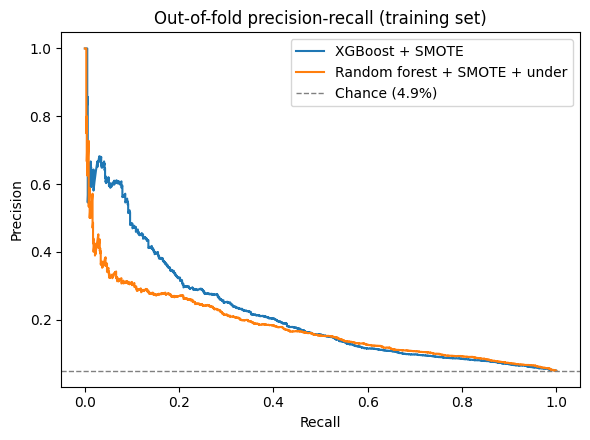

In [9]:
def best_f1_threshold(y_true, probs):
    prec, rec, thr = precision_recall_curve(y_true, probs)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i])

rows = []
for name, oof, model in [('XGBoost + SMOTE', oof_xgb, xgb_pipe), ('Random forest + SMOTE + undersampling', oof_rf, rf_pipe)]:
    t, f1_oof = best_f1_threshold(y_train, oof)
    p_test = model.predict_proba(X_test_st)[:, 1]
    for label, cut in [('0.50 (default)', 0.5), (f'{t:.2f} (tuned)', t)]:
        pred = (p_test >= cut).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
        rows.append({'Model': name, 'Threshold': label, 'Precision': precision_score(y_test, pred, zero_division=0),
                     'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred),
                     'Caught (of 245)': tp, 'False alarms (of 4,705)': fp})
thresholds = pd.DataFrame(rows)
print(thresholds.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4.5))
for name, oof in [('XGBoost + SMOTE', oof_xgb), ('Random forest + SMOTE + under', oof_rf)]:
    prec, rec, _ = precision_recall_curve(y_train, oof)
    ax.plot(rec, prec, label=name)
ax.axhline(y_train.mean(), ls='--', c='grey', lw=1, label=f'Chance ({y_train.mean():.1%})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Out-of-fold precision-recall (training set)')
ax.legend(); plt.tight_layout(); plt.show()

## 8. SHAP explanation of the XGBoost model

Mean absolute SHAP value ranks features by how much they move predictions. The direction column is the correlation between a feature's value and its SHAP value: positive means higher values push towards *distressed*.

                                               Mean |SHAP|  Direction
Months_Since_Incorp                                 1.2840       0.50
Accounts.AccountCategory_NO ACCOUNTS FILED          0.4044       0.86
Google_Overall_Rating                               0.3061      -0.57
Number of restaurants in Postcode                   0.2989      -0.87
Customer Service                                    0.2756       0.57
Value for Money                                     0.2559       0.54
Accounts.AccountCategory_MICRO ENTITY               0.2468      -0.94
Crime_per_postcode                                  0.2353      -0.23
Number of restaurants based on CH                   0.2315       0.58
Google_Price_Level                                  0.2260      -0.25
Latest_Average                                      0.2162      -0.08
Accounts.AccountCategory_TOTAL EXEMPTION FULL       0.2108      -0.98
Food and Beverage Quality                           0.2015      -0.38
Ambiance & Atmospher

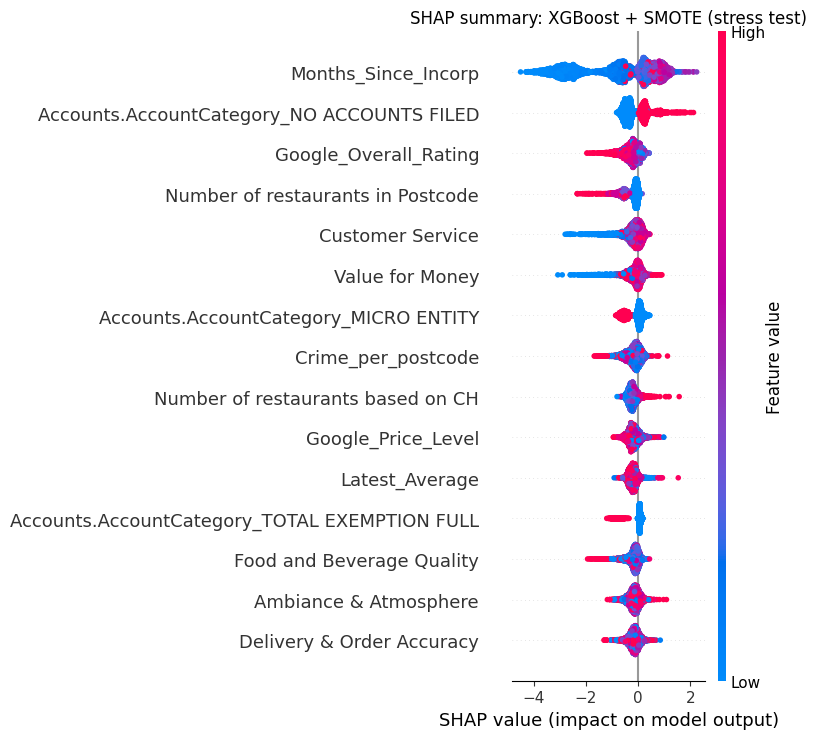

In [10]:
xgb_model = xgb_pipe.named_steps['model']
shap_values = shap.TreeExplainer(xgb_model).shap_values(X_test_st)
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=X_test_st.columns)
top = mean_abs.sort_values(ascending=False).head(15)
direction = {f: np.corrcoef(X_test_st[f], shap_values[:, X_test_st.columns.get_loc(f)])[0, 1]
             if X_test_st[f].std() > 0 else 0.0 for f in top.index}
print(pd.DataFrame({'Mean |SHAP|': top.round(4), 'Direction': pd.Series(direction).round(2)}).to_string())

shap.summary_plot(shap_values, X_test_st, max_display=15, show=False)
plt.title('SHAP summary: XGBoost + SMOTE (stress test)'); plt.tight_layout(); plt.show()

## 9. Summary

- **The original results reproduce.** Logistic regression on all features gives the same test ROC-AUC of 0.930.
- **Cross-validation is consistent with the single split.** Stress-test features, 5 folds: random forest AUC 0.770 ± 0.024 and XGBoost 0.758 ± 0.026. Average precision is about 0.19 to 0.22, roughly four times the 5% chance level.
- **Threshold tuning helps.** Choosing the threshold on out-of-fold predictions (0.24 for XGBoost) raised test F1 from 0.22 to 0.27. The model caught 73 of 245 distressed businesses instead of 36, at the cost of 218 false alarms among 4,705 healthy ones.
- **SHAP drivers (without the overdue flags):** company age is by far the strongest, followed by "no accounts filed" status, Google rating, and the number of restaurants in the same postcode. Older companies and "no accounts filed" push towards distress; higher Google ratings and more nearby restaurants push away from it. Sentiment features appear in the top 15, but their effects are small and mixed.
- **Still open:** most positives are strike-off proposals, and features and outcome come from one snapshot. A forward-looking version would build features from one snapshot and measure outcomes 12 months later.
